**FER2013 model comparison.** Run the four scripts first (mlp.py, cnn.py, qwen_zeroshot.py, qwen_finetune.py). Each one saves a JSON file in results/, and this notebook turns those files into the tables and graphs for the slides.

In [1]:
import glob
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import common

ORDER = ["mlp", "cnn_no_miopen", "cnn", "qwen_zeroshot", "qwen_finetune"]
COLORS = ["#1f77b4", "#ffbb78", "#ff7f0e", "#2ca02c", "#9467bd"]

results = [json.load(open(path)) for path in glob.glob("results/*.json")]
results.sort(key=lambda r: ORDER.index(r["model"]) if r["model"] in ORDER else len(ORDER))
names = [r["model"] for r in results]
colors = dict(zip(names, COLORS))
print(names)

['mlp', 'cnn_no_miopen', 'cnn', 'qwen_zeroshot', 'qwen_finetune']


Every model is scored again here on the same test images, so the comparison stays fair even if one script was run with --n-test.

In [2]:
data = common.load_data()
n = min(r["n_test"] for r in results)
y_true = data["y_test"][:n]
for r in results:
    r.update(common.evaluate(y_true, np.array(r["predictions"][:n])))
print(f"all models are compared on the same {n} test images")

all models are compared on the same 3573 test images


In [3]:
columns = ["accuracy", "macro_f1", "train_time_s", "inference_ms_per_image", "params", "size_mb", "peak_gpu_mb", "device"]
table = pd.DataFrame(results).set_index("model")[columns]
table.to_csv("results/summary.csv")
table

,accuracy,macro_f1,train_time_s,inference_ms_per_image,params,size_mb,peak_gpu_mb,device
model,,,,,,,,
mlp,0.482228,0.226051,50.27,0.0088,2889224,11.56,184.6,AMD Radeon RX 7800 XT
cnn_no_miopen,0.764624,0.606369,1809.51,0.2660,1469288,5.88,503.7,AMD Radeon RX 7800 XT
cnn,0.746991,0.602803,589.91,3.4323,1469288,5.88,471.3,AMD Radeon RX 7800 XT
qwen_zeroshot,0.696054,0.460688,0.00,85.9580,2208985600,4417.97,4756.8,AMD Radeon RX 7800 XT
qwen_finetune,0.805486,0.613064,6748.05,87.7248,2213343744,4435.40,10022.7,AMD Radeon RX 7800 XT


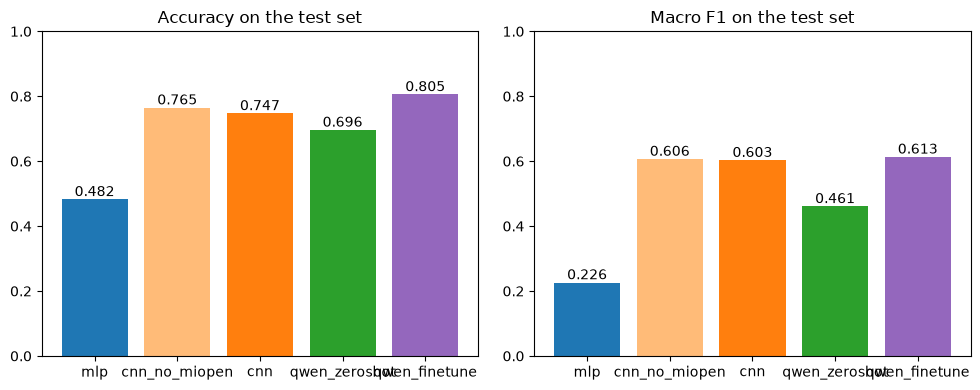

In [4]:
def bar_chart(ax, column, title, log=False):
    values = table[column]
    bars = ax.bar(values.index, values, color=[colors[name] for name in values.index])
    ax.bar_label(bars, labels=[f"{v:.3f}" if v < 10 else f"{v:,.0f}" for v in values])
    ax.set_title(title)
    if log:
        ax.set_yscale("log")


fig, axes = plt.subplots(1, 2, figsize=(10, 4))
bar_chart(axes[0], "accuracy", "Accuracy on the test set")
bar_chart(axes[1], "macro_f1", "Macro F1 on the test set")
for ax in axes:
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig("results/quality.png", dpi=150)

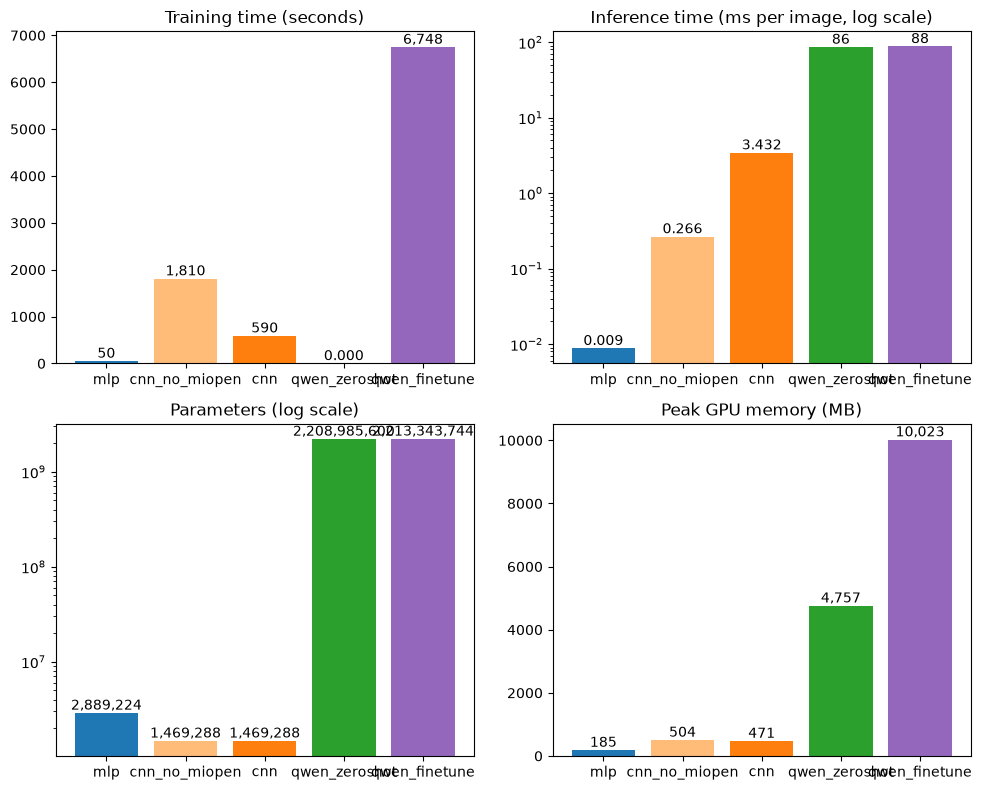

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
bar_chart(axes[0, 0], "train_time_s", "Training time (seconds)")
bar_chart(axes[0, 1], "inference_ms_per_image", "Inference time (ms per image, log scale)", log=True)
bar_chart(axes[1, 0], "params", "Parameters (log scale)", log=True)
bar_chart(axes[1, 1], "peak_gpu_mb", "Peak GPU memory (MB)")
plt.tight_layout()
plt.savefig("results/cost.png", dpi=150)

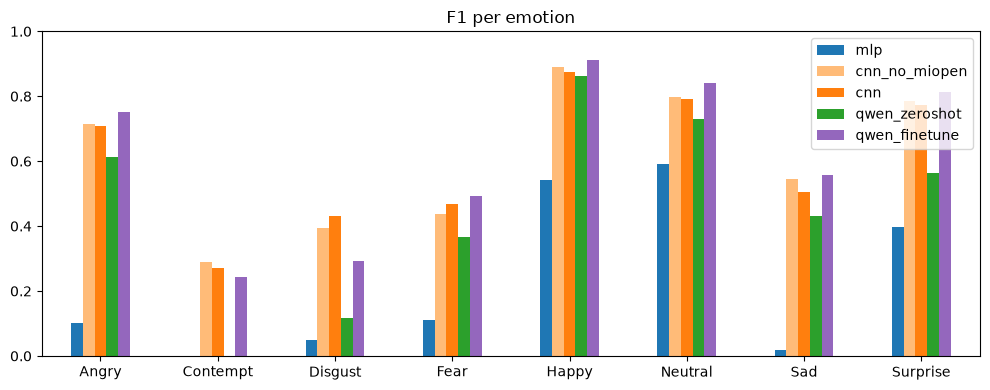

In [6]:
per_class = pd.DataFrame({r["model"]: r["per_class_f1"] for r in results})
ax = per_class.plot.bar(figsize=(10, 4), color=[colors[name] for name in per_class.columns], ylim=(0, 1), rot=0)
ax.set_title("F1 per emotion")
plt.tight_layout()
plt.savefig("results/per_class_f1.png", dpi=150)

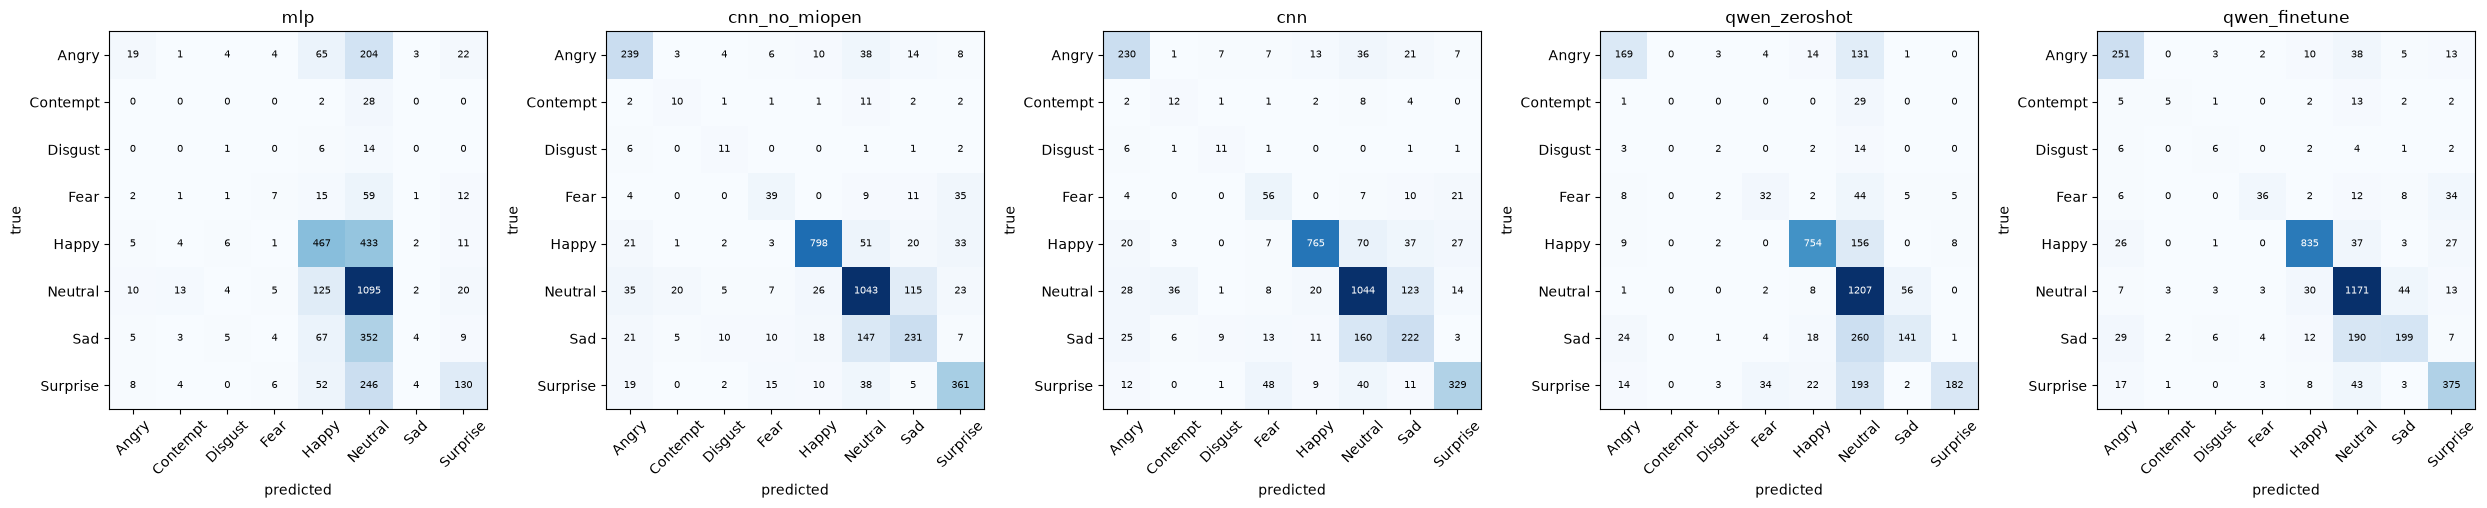

In [7]:
fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 5), squeeze=False)
for ax, r in zip(axes[0], results):
    matrix = np.array(r["confusion_matrix"])
    ax.imshow(matrix, cmap="Blues")
    ax.set_title(r["model"])
    ax.set_xticks(range(len(common.EMOTIONS)), common.EMOTIONS, rotation=45)
    ax.set_yticks(range(len(common.EMOTIONS)), common.EMOTIONS)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    for i in range(len(common.EMOTIONS)):
        for j in range(len(common.EMOTIONS)):
            text_color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
            ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=7, color=text_color)
plt.tight_layout()
plt.savefig("results/confusion_matrices.png", dpi=150)